# Load Libraries

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import MinMaxScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import mean_squared_error
from sklearn.utils import resample, shuffle
from sklearn import metrics


!pip install dmba
from dmba import classificationSummary
from dmba import gainsChart, liftChart

import seaborn as sns
import matplotlib.pylab as plt


%matplotlib inline

In [ ]:
# Mounting the Google Drive, the file path might be different for each of us
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Load SBA Clean
SBA_df = pd.read_csv('/content/drive/My Drive/MSBA/MSBA BA Project/SBA_clean2.csv')
SBA_df.head()

,UrbanRural,RevLineCr,DisbursementGross,MIS_Status,SBA_Appv,Term_Category,Recession
0,0,0,60000.0,0,48000.0,Below 10 years,0
1,0,0,40000.0,0,32000.0,Below 10 years,0
2,0,0,287000.0,0,215250.0,Above 10 years,0
3,0,0,517000.0,0,387750.0,Below 10 years,0
4,0,0,45000.0,0,36000.0,Below 10 years,0


In [ ]:
# Make Dummies
SBA_df2 = SBA_df.copy()

# Change dtype to category
SBA_df2 = pd.get_dummies(SBA_df2, columns=['UrbanRural', 'RevLineCr', 'Term_Category', 'Recession'], drop_first=True, dtype=int)

# Remove spaces in headers
SBA_df2.columns = SBA_df2.columns.str.replace(' ', '_')
SBA_df2.head()

,DisbursementGross,MIS_Status,SBA_Appv,UrbanRural_1,UrbanRural_2,RevLineCr_1,Term_Category_Below_10_years,Recession_1
0,60000.0,0,48000.0,0,0,0,1,0
1,40000.0,0,32000.0,0,0,0,1,0
2,287000.0,0,215250.0,0,0,0,0,0
3,517000.0,0,387750.0,0,0,0,1,0
4,45000.0,0,36000.0,0,0,0,1,0


# Scale the data

In [ ]:
# Separate X and y
X = SBA_df2.drop(columns=['MIS_Status'])
y = SBA_df2['MIS_Status']

# Split into train and valid
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.4, random_state=1)

# Shapes
print(X_train.shape)
print(X_valid.shape)
print(y_train.shape)
print(y_valid.shape)

(284117, 7)
(189412, 7)
(284117,)
(189412,)


In [ ]:
# Scale continuous variables

# Standardize
scaler = MinMaxScaler()
scaler.fit(X_train)

# X to Scale
X_to_scale = ['DisbursementGross', 'SBA_Appv']


# Initialize Scaler
scaleInput = MinMaxScaler(feature_range=(0, 1), clip=True)
X_train_scale = X_train[X_to_scale]

# Fit and transform
X_train_scaled = scaleInput.fit_transform(X_train_scale)

# Drop these from X train
X_train.drop(columns=X_to_scale, inplace=True)

# Append back
X_train = np.append(X_train, X_train_scaled, axis=1)

# Turn into df
X_train = pd.DataFrame(X_train, columns=X.columns)

# Transform X_valid
X_valid_scale = X_valid[X_to_scale]
X_valid_scaled = scaleInput.transform(X_valid_scale)

# Drop these from X valid
X_valid.drop(columns=X_to_scale, inplace=True)

# Append back
X_valid = np.append(X_valid, X_valid_scaled, axis=1)

# Turn into df
X_valid = pd.DataFrame(X_valid, columns=X.columns)

# Verify
print(X_train.head())
print(X_valid.head())

   DisbursementGross  SBA_Appv  UrbanRural_1  UrbanRural_2  RevLineCr_1  \
0                1.0       0.0           0.0           1.0          1.0   
1                1.0       0.0           0.0           0.0          0.0   
2                1.0       0.0           0.0           1.0          1.0   
3                1.0       0.0           0.0           1.0          1.0   
4                1.0       0.0           0.0           1.0          0.0   

   Term_Category_Below_10_years  Recession_1  
0                      0.005819     0.006745  
1                      0.052078     0.062957  
2                      0.001433     0.001644  
3                      0.002389     0.002756  
4                      0.011945     0.013867  
   DisbursementGross  SBA_Appv  UrbanRural_1  UrbanRural_2  RevLineCr_1  \
0                1.0       0.0           1.0           1.0          0.0   
1                0.0       1.0           1.0           1.0          1.0   
2                1.0       0.0           0

# Finding best parameters

Used Random Search and GridSearch. Random Search runs after a few hours, Grid Search takes much longer. Searched up to 8 nodes because we have 7 features. Reduced the folds to 5.

## Searching optimal node count within 1 layer

In [ ]:
# Random Search
# Ensure X_train and y_train are aligned
X_train, y_train = X_train.reset_index(drop=True), y_train.reset_index(drop=True)

# Split the data into classes
X_train_0 = X_train[y_train == 0]
X_train_1 = X_train[y_train == 1]

y_train_0 = y_train[y_train == 0]
y_train_1 = y_train[y_train == 1]

# Oversample class 1 by replicating its rows
X_train_1_oversampled = np.repeat(X_train_1.values, 5, axis=0)
y_train_1_oversampled = np.repeat(y_train_1.values, 5, axis=0)

# Combine back the oversampled data
X_train_balanced = np.vstack((X_train_0.values, X_train_1_oversampled))
y_train_balanced = np.concatenate((y_train_0.values, y_train_1_oversampled))

# Shuffle the dataset
X_train_balanced, y_train_balanced = shuffle(X_train_balanced, y_train_balanced, random_state=1)

# Reduce the size of the dataset for faster training
X_subset, _, y_subset, _ = train_test_split(
    X_train_balanced, y_train_balanced, train_size=0.2, random_state=1, stratify=y_train_balanced
)

# Define parameter distributions
param_distributions = {
    'hidden_layer_sizes': [(i,) for i in range(1, 9)],  # One layer with nodes from 1 to 8
    'activation': ['relu', 'tanh', 'logistic'],  # Activation functions
    'solver': ['lbfgs', 'adam', 'sgd']  # Solvers
}

# Initialize RandomizedSearchCV
randomSearch = RandomizedSearchCV(
    estimator=MLPClassifier(random_state=1, max_iter=5000),
    param_distributions=param_distributions,
    n_iter=50,
    cv=5,
    n_jobs=-1,
    random_state=1,
    return_train_score=True
)

# Fit the model
randomSearch.fit(X_subset, y_subset)

# Print results
print('Best score: ', randomSearch.best_score_)
print('Best hidden layer sizes: ', randomSearch.best_params_['hidden_layer_sizes'])
print('Best activation function: ', randomSearch.best_params_['activation'])
print('Best solver: ', randomSearch.best_params_['solver'])

Best score:  0.7097452448593535
Best hidden layer sizes:  (8,)
Best activation function:  tanh
Best solver:  lbfgs


In [ ]:
# Grid Search
# Ensure X_train and y_train are aligned
X_train, y_train = X_train.reset_index(drop=True), y_train.reset_index(drop=True)

# Split the data into classes
X_train_0 = X_train[y_train == 0]
X_train_1 = X_train[y_train == 1]

y_train_0 = y_train[y_train == 0]
y_train_1 = y_train[y_train == 1]

# Oversample class 1 by replicating its rows
X_train_1_oversampled = np.repeat(X_train_1.values, 5, axis=0)
y_train_1_oversampled = np.repeat(y_train_1.values, 5, axis=0)

# Combine back the oversampled data
X_train_balanced = np.vstack((X_train_0.values, X_train_1_oversampled))
y_train_balanced = np.concatenate((y_train_0.values, y_train_1_oversampled))

# Shuffle the dataset
X_train_balanced, y_train_balanced = shuffle(X_train_balanced, y_train_balanced, random_state=1)

# Reduce the size of the dataset for faster training
X_subset, _, y_subset, _ = train_test_split(
    X_train_balanced, y_train_balanced, train_size=0.2, random_state=1, stratify=y_train_balanced
)

# Define parameter grid (use param_grid, not param_distributions)
param_grid = {
    'hidden_layer_sizes': [(i,) for i in range(1, 9)],  # One layer with nodes from 1 to 8
    'activation': ['relu', 'tanh', 'logistic'],  # Activation functions
    'solver': ['lbfgs', 'adam', 'sgd']  # Solvers
}

# Initialize GridSearchCV
gridSearch = GridSearchCV(
    estimator=MLPClassifier(random_state=1, max_iter=5000),
    param_grid=param_grid,
    cv=5,
    n_jobs=-1,
    return_train_score=True
)

# Fit the model
gridSearch.fit(X_subset, y_subset)

# Print results
print('Best score: ', gridSearch.best_score_)
print('Best hidden layer sizes: ', gridSearch.best_params_['hidden_layer_sizes'])
print('Best activation function: ', gridSearch.best_params_['activation'])
print('Best solver: ', gridSearch.best_params_['solver'])

Best score:  0.7097452448593535
Best hidden layer sizes:  (8,)
Best activation function:  tanh
Best solver:  lbfgs


Both Random Search and Grid Search found the same optimal model.

## Searching optimal node count within 2 layers

In [ ]:
# Random Search
# Ensure X_train and y_train are aligned
X_train, y_train = X_train.reset_index(drop=True), y_train.reset_index(drop=True)

# Split the data into classes
X_train_0 = X_train[y_train == 0]
X_train_1 = X_train[y_train == 1]

y_train_0 = y_train[y_train == 0]
y_train_1 = y_train[y_train == 1]

# Oversample class 1 by replicating its rows
X_train_1_oversampled = np.repeat(X_train_1.values, 5, axis=0)
y_train_1_oversampled = np.repeat(y_train_1.values, 5, axis=0)

# Combine back the oversampled data
X_train_balanced = np.vstack((X_train_0.values, X_train_1_oversampled))
y_train_balanced = np.concatenate((y_train_0.values, y_train_1_oversampled))

# Shuffle the dataset
X_train_balanced, y_train_balanced = shuffle(X_train_balanced, y_train_balanced, random_state=1)

# Reduce the size of the dataset for faster training
X_subset, _, y_subset, _ = train_test_split(
    X_train_balanced, y_train_balanced, train_size=0.2, random_state=1, stratify=y_train_balanced
)

# Define the parameter distribution
param_distributions = {
    'hidden_layer_sizes': [(i, j) for i in range(1, 9) for j in range(1, 9)],  # 2 layers with nodes from 1 to 8
    'activation': ['relu', 'tanh', 'logistic'],  # Activation functions
    'solver': ['lbfgs', 'adam', 'sgd']  # Solvers
}

# Initialize RandomizedSearchCV
randomSearch = RandomizedSearchCV(
    estimator=MLPClassifier(random_state=1, max_iter=10000),
    param_distributions=param_distributions,
    n_iter=50,  # Number of random configurations to try
    cv=5,  # Cross-validation folds
    n_jobs=-1,  # Use all available cores
    random_state=1,
    return_train_score=True
)

# Fit the model
randomSearch.fit(X_subset, y_subset)

# Print the best score and parameters
print('Best score: ', randomSearch.best_score_)
print('Best hidden layer size: ', randomSearch.best_params_['hidden_layer_sizes'])
print('Best activation function: ', randomSearch.best_params_['activation'])
print('Best solver: ', randomSearch.best_params_['solver'])

Best score:  0.710773237698911
Best hidden layer size:  (4, 8)
Best activation function:  tanh
Best solver:  lbfgs


In [ ]:
# Grid Search
# Ensure X_train and y_train are aligned
X_train, y_train = X_train.reset_index(drop=True), y_train.reset_index(drop=True)

# Split the data into classes
X_train_0 = X_train[y_train == 0]
X_train_1 = X_train[y_train == 1]

y_train_0 = y_train[y_train == 0]
y_train_1 = y_train[y_train == 1]

# Oversample class 1 by replicating its rows
X_train_1_oversampled = np.repeat(X_train_1.values, 5, axis=0)
y_train_1_oversampled = np.repeat(y_train_1.values, 5, axis=0)

# Combine back the oversampled data
X_train_balanced = np.vstack((X_train_0.values, X_train_1_oversampled))
y_train_balanced = np.concatenate((y_train_0.values, y_train_1_oversampled))

# Shuffle the dataset
X_train_balanced, y_train_balanced = shuffle(X_train_balanced, y_train_balanced, random_state=1)

# Reduce the size of the dataset for faster training
X_subset, _, y_subset, _ = train_test_split(
    X_train_balanced, y_train_balanced, train_size=0.2, random_state=1, stratify=y_train_balanced
)

# Define the parameter grid for grid search
param_grid = {
    'hidden_layer_sizes': [(i, j) for i in range(1, 9) for j in range(1, 9)],  # 2 layers with nodes from 1 to 8
    'activation': ['relu', 'tanh', 'logistic'],  # Activation functions
    'solver': ['lbfgs', 'adam', 'sgd']  # Solvers
}

# Initialize GridSearchCV
gridSearch = GridSearchCV(
    estimator=MLPClassifier(random_state=1, max_iter=10000),
    param_grid=param_grid,
    cv=5,  # Cross-validation folds
    n_jobs=-1,  # Use all available cores
    return_train_score=True
)

# Fit the model
gridSearch.fit(X_subset, y_subset)

# Print the best score and parameters
print('Best score: ', gridSearch.best_score_)
print('Best hidden layer size: ', gridSearch.best_params_['hidden_layer_sizes'])
print('Best activation function: ', gridSearch.best_params_['activation'])
print('Best solver: ', gridSearch.best_params_['solver'])

KeyboardInterrupt: 

The Random Search took over 2.5 hrs to compute. Grid Search failed to compute (exceed 5+ hours, runtime error).

**The best model was found using Random Search. The model was 2 layers with 4, 8 nodes. The best activation function was tanh with the best solver as lbfgs.**

# Create model

In [ ]:
# Fit two-layer model
clf = MLPClassifier(hidden_layer_sizes=(4, 8), activation='tanh', solver='lbfgs', random_state=1, max_iter=10000)
clf.fit(X_train, y_train)

MLPClassifier(activation='tanh', hidden_layer_sizes=(4, 8), max_iter=10000,
              random_state=1, solver='lbfgs')

# Model Performance

In [ ]:
# Classification Summary valid
classificationSummary(y_valid, clf.predict(X_valid))

Confusion Matrix (Accuracy 0.7796)

       Prediction
Actual      0      1
     0 142466   4753
     1  36988   5205


Accuracy:  0.7796285346229384


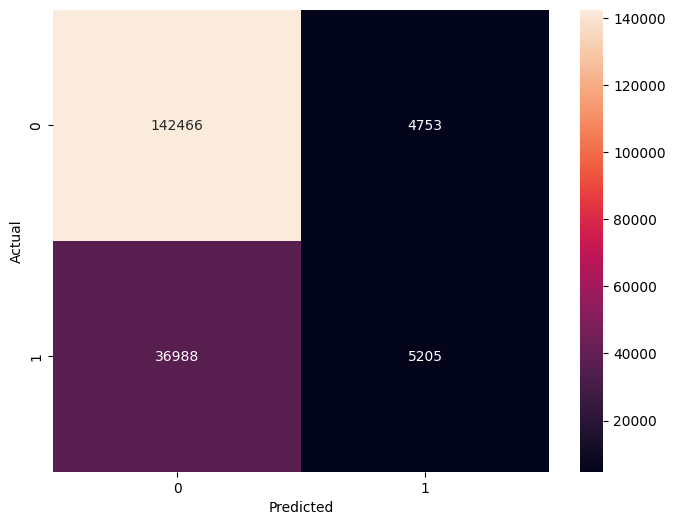

In [ ]:
#Confusion Matrix
y_pred = clf.predict(X_valid)
confusion_matrix = pd.crosstab(y_valid, y_pred, rownames=['Actual'], colnames=['Predicted'])
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix, annot=True, fmt='g')
print('Accuracy: ',metrics.accuracy_score(y_valid, y_pred))
plt.show()

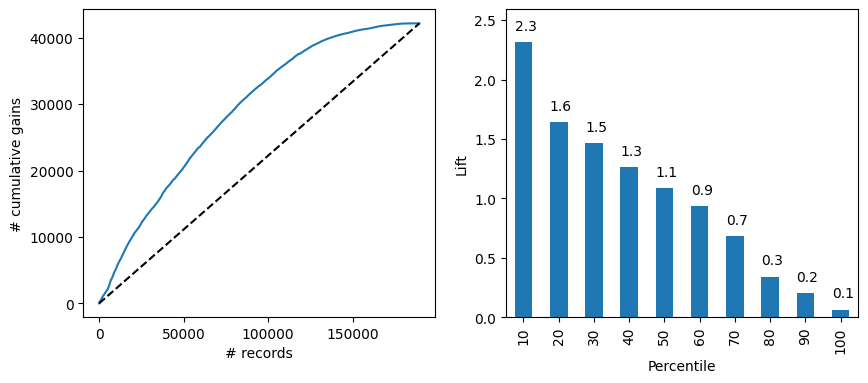

In [ ]:
# Lift and Decile Charts

# Step 1: Calculate predicted probabilities for the training set
valid_proba = clf.predict_proba(X_valid)

# Step 2: Create a DataFrame with actual, predicted probabilities, and predicted labels for the training set
valid_result = pd.DataFrame({
    'actual': y_valid,
    'p(0)': [p[0] for p in valid_proba],
    'p(1)': [p[1] for p in valid_proba],
    'predicted': clf.predict(X_valid)
})

# Step 3: Sort DataFrame by p(1)
valid_df = valid_result.sort_values(by=['p(1)'], ascending=False)

# Step 4: Plot Gains and Lift charts for the training set
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

gainsChart(valid_df.actual, ax=axes[0])
liftChart(valid_df.actual, title=False)

plt.show()

Overall the model predicts 2.3 times better in the first decile. The next 20-50% bars also predict better than a random 10% of samples from the data.

In [ ]:
# Precision (Positive class is 'Acceptors')
precision = metrics.precision_score(y_valid, y_pred, pos_label=1)

# Recall (Sensitivity) or True Positive Rate
recall = metrics.recall_score(y_valid, y_pred, pos_label=1)

# F1 Score (harmonic mean of Precision and Recall)
f1 = metrics.f1_score(y_valid, y_pred, pos_label=1)


# Calculate the confusion matrix
cm = metrics.confusion_matrix(y_valid, y_pred)

# Extract True Negatives (TN), False Positives (FP), False Negatives (FN), True Positives (TP)
TN, FP, FN, TP = cm.ravel()

# Specificity (True Negative Rate)
specificity = TN / (TN + FP)

# Scores dataframe
scores = pd.DataFrame({
    'Model': ['Descriminant Analysis'],
    'Precision': [precision],
    'Recall': [recall],
    'F1 Score': [f1],
    'Specificity': [specificity]
})

scores

,Model,Precision,Recall,F1 Score,Specificity
0,Descriminant Analysis,0.522695,0.123362,0.199613,0.967715


# Optimal cut off with Max Net Profit

In [ ]:
# Set up
disbursement_gross = np.array(X_train['DisbursementGross'])
actual_y = np.array(y_train)

# Get predicted probabilities for the positive class
pred_prob = clf.predict_proba(X_train)[:, 1]  # Probabilities for class 1 ("Default")

# Define thresholds and initialize net profits
thresholds = np.linspace(0.01, 0.99, 100)  # Range of thresholds from 0.01 to 0.99
net_profits = []

# Loop over each threshold and calculate the net profit
for threshold in thresholds:
    # Classify based on the threshold
    pred_y = (pred_prob >= threshold).astype(int)

    # Calculate net profit
    # Case 1: Correctly classified as "Paid in full" (Actual = 0, Predicted = 0)
    profit_case1 = 0.05 * disbursement_gross[(actual_y == 0) & (pred_y == 0)]

    # Case 2: Incorrectly classified as "Paid in full" (Actual = 1, Predicted = 0)
    loss_case2 = -0.05 * disbursement_gross[(actual_y == 1) & (pred_y == 0)] * 5

    # Case 3: Correctly classified as "Default" (Actual = 1, Predicted = 1)
    profit_case3 = 0  # No profit or loss for this case

    # Case 4: Incorrectly classified as "Default" (Actual = 0, Predicted = 1)
    loss_case4 = 0  # No profit or loss for this case

    # Total net profit for this threshold
    net_profit = np.sum(profit_case1) + np.sum(loss_case2) + profit_case3 + loss_case4
    net_profits.append(net_profit)

# Convert net_profits to a numpy array for easier analysis
net_profits = np.array(net_profits)

# Find the threshold that maximizes the net profit
best_threshold = thresholds[np.argmax(net_profits)]
max_net_profit = np.max(net_profits)

# Calculate the total sum of net profits
total_net_profit = np.sum(net_profits)

# Output the best threshold and corresponding net profit
print(f"Best Threshold: {best_threshold:.2f}")
print(f"Maximum Net Profit: {max_net_profit:,.2f} USD")
print(f"Total Sum of Net Profits Across All Thresholds: {total_net_profit:,.2f} USD")

Best Threshold: 0.19
Maximum Net Profit: 711.80 USD
Total Sum of Net Profits Across All Thresholds: -375,847.55 USD
